In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd

# =========修改为自己学号=========
STUDENT_ID = 20244080226

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

# 设置全局随机种子，保证随机实验可复现
np.random.seed(42)


[Conda 环境] base
[学号] 20244080226
[机器指纹] 068b3410f591ad41
[RUN_ID] 20244080226-068b3410f591ad41


## 实验一：NumPy数组，数据类型与索引

In [2]:
# 1 创建整数、浮点数、布尔数组
arr_int = np.array([1,2,3,4], dtype=int)
arr_float = np.array([1.1,2.2,3.3], dtype=float)
arr_bool = np.array([True, False, True])

print("整数数组：")
print(f"dtype={arr_int.dtype}, shape={arr_int.shape}, ndim={arr_int.ndim}")
print("浮点数数组：")
print(f"dtype={arr_float.dtype}, shape={arr_float.shape}, ndim={arr_float.ndim}")
print("布尔数组：")
print(f"dtype={arr_bool.dtype}, shape={arr_bool.shape}, ndim={arr_bool.ndim}")


整数数组：
dtype=int64, shape=(4,), ndim=1
浮点数数组：
dtype=float64, shape=(3,), ndim=1
布尔数组：
dtype=bool, shape=(3,), ndim=1


解释：所有元素必须是相同数据类型，内存连续，计算速度快；Python 列表可以存放不同类型对象，内存分散，循环运算慢。

In [3]:
# 2 arange(12) reshape
a1 = np.arange(12)
a_34 = a1.reshape(3,4)
a_232 = a1.reshape(2,3,2)
print("原始a1：", a1)
print("\n(3,4):\n", a_34)
print("\n(2,3,2):\n", a_232)


原始a1： [ 0  1  2  3  4  5  6  7  8  9 10 11]

(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


解释：reshape 总元素数必须不变，`新shape各维度乘积 = 原数组size`；12 =3*4 =2*3*2。

In [4]:
#3 对(3,4)数组索引
arr = np.arange(12).reshape(3,4)
print("原数组(3,4):\n", arr)

row2 = arr[1, :]          # 第2行，索引从0开始
col1_3 = arr[:, 0:3]      # 第1~3列
gt6 = arr[arr>6]

print("\n第2行：", row2, "shape:", row2.shape)
print("\n第1‑3列：\n", col1_3, "shape:", col1_3.shape)
print("\n大于6的元素：", gt6, "shape:", gt6.shape)


原数组(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第2行： [4 5 6 7] shape: (4,)

第1‑3列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape: (3, 3)

大于6的元素： [ 7  8  9 10 11] shape: (5,)


In [5]:
#4 布尔索引 或 / 且
ar = np.arange(10)
cond1 = (ar <2) | (ar>7)
res1 = ar[cond1]
cond2 = np.logical_and(ar>3, ar<7)
res2 = ar[cond2]
print("小于2或大于7：", res1)
print("大于3且小于7：", res2)


小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]


In [6]:
#5 逐元素乘法 vs 矩阵乘法
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])

elem1 = A * B
elem2 = np.multiply(A,B)
mat1 = A @ B
mat2 = np.matmul(A,B)

print("A*B逐元素:\n", elem1)
print("np.multiply:\n", elem2)
print("@矩阵乘法:\n", mat1)
print("np.matmul:\n", mat2)


A*B逐元素:
 [[ 5 12]
 [21 32]]
np.multiply:
 [[ 5 12]
 [21 32]]
@矩阵乘法:
 [[19 22]
 [43 50]]
np.matmul:
 [[19 22]
 [43 50]]


## 实验二：随机抽样、统计与缺失值

In [7]:
#1 模拟成绩
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

n = len(scores)
min_s = scores.min()
max_s = scores.max()
mean_s = scores.mean()
std_s = scores.std()
range_s = max_s - min_s

print(f"样本数:{n}, min={min_s:.2f}, max={max_s:.2f}, mean={mean_s:.2f}, std={std_s:.2f}, 极差={range_s:.2f}")


样本数:1000, min=37.59, max=100.00, mean=70.18, std=9.76, 极差=62.41


In [8]:
#2 不放回抽样；均匀、加权抽样
pop = np.arange(1,11)
# 均匀不放回抽5
sample_uniform = np.random.choice(pop, size=5, replace=False)
# 按数值大小加权抽样，p和pop一一对应
p_weight = pop / pop.sum()
sample_weighted = np.random.choice(pop, size=5, replace=False, p=p_weight)

print("总体：", pop)
print("均匀抽样：", sample_uniform)
print("加权抽样：", sample_weighted)


总体： [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样： [ 4  9  2  6 10]
加权抽样： [10  2  8  9  6]


In [9]:
#3 permutation(副本) vs shuffle(原地修改)
arr_orig = np.array([1,2,3,4,5])
arr_copy = arr_orig.copy()

shuffled_copy = np.random.permutation(arr_copy)
print("permutation副本模式：")
print("原数组：", arr_copy)
print("返回打乱副本：", shuffled_copy)

arr_inplace = np.array([1,2,3,4,5])
np.random.shuffle(arr_inplace)
print("\nshuffle原地打乱：")
print("打乱后原数组：", arr_inplace)


permutation副本模式：
原数组： [1 2 3 4 5]
返回打乱副本： [5 1 3 2 4]

shuffle原地打乱：
打乱后原数组： [1 5 2 4 3]


`np.random.permutation` 返回新数组，**不改动原始数组**；
`np.random.shuffle` **直接修改原数组，无返回值**。

In [10]:
#4 设置缺失值nan
scores_nan = scores.copy()
#索引9,19,29对应第10,20,30个元素
scores_nan[[9,19,29]] = np.nan

mean_normal = scores_nan.mean()        #普通mean，遇到nan结果为nan
mean_nanignore = np.nanmean(scores_nan) #忽略nan求均值
nan_count = np.isnan(scores_nan).sum()

print(f"普通mean(含nan): {mean_normal}")
print(f"np.nanmean忽略缺失值: {mean_nanignore:.2f}")
print(f"缺失值数量：{nan_count}")


普通mean(含nan): nan
np.nanmean忽略缺失值: 70.20
缺失值数量：3


解释：普通 numpy 统计函数遇到`np.nan`，结果直接返回 nan；需要使用`np.nanmean / np.nanstd`等系列函数跳过缺失值计算。

In [11]:
#5 构造内存表格，供实验4使用，不写入磁盘
df_score = pd.DataFrame({
    "index_id": np.arange(len(scores_nan)),
    "score": scores_nan
})

print(df_score.head())

   index_id      score
0         0  74.967142
1         1  68.617357
2         2  76.476885
3         3  85.230299
4         4  67.658466


## 实验 三：SciPy 数值计算与 Matplotlib 可视化

In [12]:
from scipy import linalg, optimize, stats

#1 解线性方程组
A_mat = np.array([[3, 1], [1, 2]])
b_vec = np.array([9, 8])
sol = linalg.solve(A_mat, b_vec)
x_sol, y_sol = sol[0], sol[1]
print(f"方程组解 x={x_sol:.2f}, y={y_sol:.2f}")
#代入验证
print("代入验证：3*x+y =", 3*x_sol+y_sol)
print("代入验证：x+2*y =", x_sol+2*y_sol)


方程组解 x=2.00, y=3.00
代入验证：3*x+y = 9.0
代入验证：x+2*y = 8.0


In [13]:
#2 求 x^2‑2=0 的根
def f(x):
    return x**2 - 2

#初值为2求正根
res_pos = optimize.root(f, x0=2)
#初值‑2求负根
res_neg = optimize.root(f, x0=-2)

print("正根求解成功?", res_pos.success, "根x=", res_pos.x, "f(x)=", f(res_pos.x))
print("负根求解成功?", res_neg.success, "根x=", res_neg.x, "f(x)=", f(res_neg.x))


正根求解成功? True 根x= [1.41421356] f(x)= [8.8817842e-16]
负根求解成功? True 根x= [-1.41421356] f(x)= [8.8817842e-16]


In [14]:
#3 f(x)=x²+x+2求极小
def func_min(x):
    return x**2 + x + 2

res_min = optimize.minimize(func_min, x0=0)
print("极小点x:", res_min.x)
print("极小函数值：", res_min.fun)
#解析解：导数2x+1=0 → x=-0.5，f(-0.5)=1.75
print("解析极小点x=-0.5，解析值=1.75")


极小点x: [-0.50000001]
极小函数值： 1.75
解析极小点x=-0.5，解析值=1.75


In [15]:
#4 独立样本t检验
np.random.seed(42)
s1 = np.random.normal(loc=0, scale=1, size=100)
s2 = np.random.normal(loc=1, scale=1, size=100)
t_result = stats.ttest_ind(s1, s2)
print(f"t统计量={t_result.statistic:.3f}, p值={t_result.pvalue:.4f}")
alpha = 0.05
if t_result.pvalue < alpha:
    print(f"p<{alpha}，拒绝原假设，两组均值存在显著差异")
else:
    print(f"p≥{alpha}，不能拒绝原假设，无显著差异")


t统计量=-8.551, p值=0.0000
p<0.05，拒绝原假设，两组均值存在显著差异


C:\Users\李小美.LAPTOP-98GU13DE\AppData\Local\Temp\ipykernel_19636\4069192114.py:16: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\李小美.LAPTOP-98GU13DE\AppData\Local\Temp\ipykernel_19636\4069192114.py:16: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\李小美.LAPTOP-98GU13DE\AppData\Local\Temp\ipykernel_19636\4069192114.py:16: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\李小美.LAPTOP-98GU13DE\AppData\Local\Temp\ipykernel_19636\4069192114.py:16: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\李小美.LAPTOP-98GU13DE\AppData\Local\Temp\ipykernel_19636\4069192114.py:16: UserWarning: Glyph 32489 (\N{CJK UNIFIED IDEOGRAPH-7EE9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\李小美.LAPTOP-98GU1

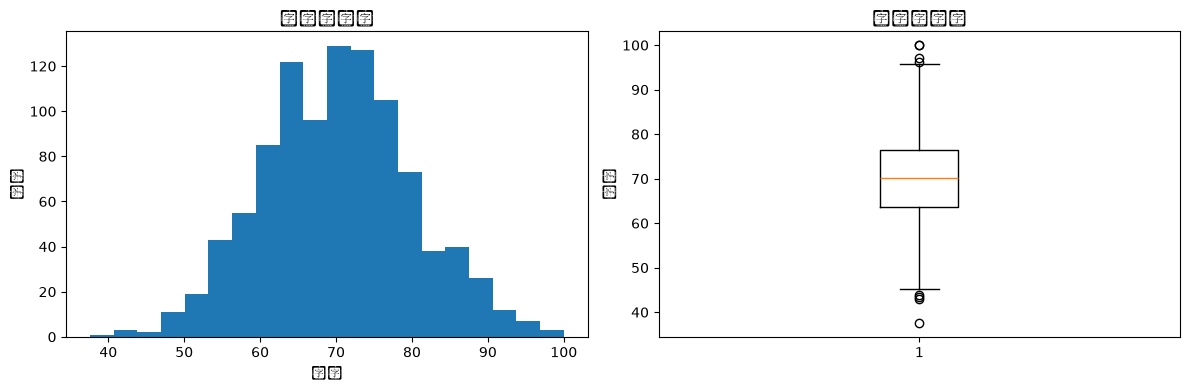

D:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
D:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20687 (\N{CJK UNIFIED IDEOGRAPH-50CF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


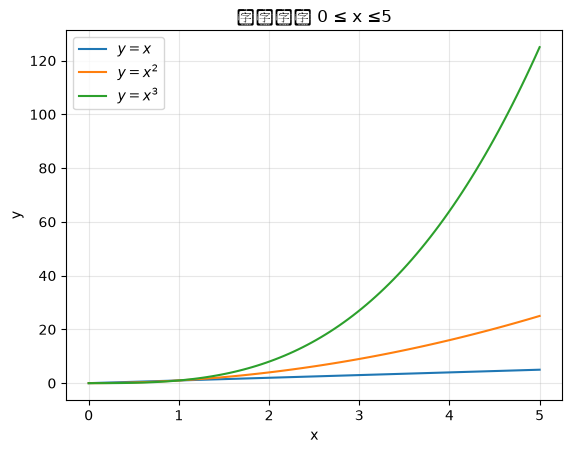

In [16]:
#5 matplotlib绘图
# ---直方图与箱线图，过滤nan
valid_scores = scores_nan[~np.isnan(scores_nan)]

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.hist(valid_scores, bins=20)
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")

plt.subplot(1,2,2)
plt.boxplot(valid_scores)
plt.title("成绩箱线图")
plt.ylabel("分数")
plt.tight_layout()
plt.show()

# y=x, y=x², y=x³，0~5
x = np.linspace(0, 5, 100)
y1 = x
y2 = x**2
y3 = x**3

plt.figure()
plt.plot(x, y1, label="$y=x$")
plt.plot(x, y2, label="$y=x^2$")
plt.plot(x, y3, label="$y=x^3$")
plt.title("函数图像 0 ≤ x ≤5")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## 实验 四：pandas Series、DataFrame

In [17]:
#1 创建DataFrame
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records)
df = df.set_index("Name")

#新增总分、平均分
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n基本统计信息：")
print(df.describe())


行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [18]:
#2 loc iloc读取Carol；筛选平均分>=80
# loc按标签；iloc按数字位置
rec_loc = df.loc["Carol"]
#找Carol的数字索引
carol_pos = df.index.get_loc("Carol")
rec_iloc = df.iloc[carol_pos]
print("loc读取Carol:\n", rec_loc)
print("\niloc读取Carol:\n", rec_iloc)

high_avg = df[df["Average"] >= 80]
print("\n平均分>=80学生：")
print(high_avg)


loc读取Carol:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc读取Carol:
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分>=80学生：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [19]:
#3 axis=0列均值；axis=1行均值
col_mean = df[["Math","English","Python"]].mean(axis=0)
row_mean = df[["Math","English","Python"]].mean(axis=1)
print("各科列均值(axis=0):")
print(col_mean)
print("\n每个学生行均值(axis=1):")
print(row_mean)


各科列均值(axis=0):
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每个学生行均值(axis=1):
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [20]:
#4 apply求每行最高分；agg每科min mean max；rank排名
df["max_score"] = df[["Math","English","Python"]].apply(lambda row: row.max(), axis=1)
print("每行最高分:\n", df["max_score"])

stat_agg = df[["Math","English","Python"]].agg(["min","mean","max"])
print("\n每科agg统计：")
print(stat_agg)

#Math列排名，数字越大名次越前
df["math_rank"] = df["Math"].rank(ascending=False)
print("\nMath排名：")
print(df[["Math","math_rank"]])


每行最高分:
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: max_score, dtype: int64

每科agg统计：
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Math排名：
       Math  math_rank
Name                  
Alice    88        2.0
Bob      72        5.0
Carol    91        1.0
David    65        6.0
Eva      79        4.0
Frank    84        3.0


In [21]:
#5 groupby分组，transform
group_obj = df.groupby("Group")
print("每组人数：")
print(group_obj.size())
print("\n每组三科平均分：")
print(group_obj[["Math","English","Python"]].mean())

#transform增加组内Python平均分到每一行
df["group_python_mean"] = group_obj["Python"].transform("mean")
print("\n增加组Python平均分后：")
print(df[["Group","Python","group_python_mean"]])


每组人数：
Group
A    3
B    3
dtype: int64

每组三科平均分：
            Math    English     Python
Group                                 
A      79.666667  83.333333  87.000000
B      80.000000  78.333333  80.333333

增加组Python平均分后：
      Group  Python  group_python_mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [22]:
#6 filter筛选组：组Python平均分>=80
def group_cond(subdf):
    return subdf["Python"].mean() >= 80

df_filtered = group_obj.filter(group_cond)
print("filter保留Python组平均分>=80的数据：")
print(df_filtered)


filter保留Python组平均分>=80的数据：
      Group  Math  English  Python  Total    Average  max_score  math_rank  \
Name                                                                         
Alice     A    88       90      95    273  91.000000         95        2.0   
Bob       A    72       68      80    220  73.333333         80        5.0   
Carol     B    91       85      89    265  88.333333         91        1.0   
David     B    65       73      70    208  69.333333         73        6.0   
Eva       A    79       92      86    257  85.666667         92        4.0   
Frank     B    84       77      82    243  81.000000         84        3.0   

       group_python_mean  
Name                      
Alice          87.000000  
Bob            87.000000  
Carol          80.333333  
David          80.333333  
Eva            87.000000  
Frank          80.333333  


In [23]:
#7 协方差矩阵、皮尔逊相关矩阵
subjects = df[["Math","English","Python"]]
cov_mat = subjects.cov()
corr_mat = subjects.corr()
print("协方差矩阵：\n", cov_mat)
print("\n皮尔逊相关系数矩阵：\n", corr_mat)


协方差矩阵：
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667

皮尔逊相关系数矩阵：
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000


协方差符号为正，代表两个科目成绩同向变化（一科高另一科倾向高）；协方差数值受量纲影响。
皮尔逊相关系数取值 [-1,1]；越接近 1 强正相关，越接近‑1 强负相关，接近 0 无线性相关。